# ADP 21회 보충 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: adp_21_summary.pdf pp.7~8 (인쇄물 14~16/16)

원 자료 조건: 요약 자료에 실제 제시된 예제 30명 수치입니다. 실제 21회 시험 데이터라고 단정하지 않습니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'21회/보충';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 성별과 여행 빈도

sex 두 범주·travel 세 범주의 균형 2×3 설계로 points(1~9)를 조사했다. 독립 관측·정규 오차·등분산을 작업 가정한다. 셀당 표본이 작고 점수가 순서 척도일 수 있는 한계가 있다. 유의수준은 5%다.

자료: travel_example.csv

### 4-1

성별 효과가 여행 빈도에 따라 달라지는지 적절한 방법으로 평가하시오. 두 주효과·상호작용의 가설·통계량·p-value·기각 여부와 셀 평균·상호작용 그림을 제시하고 점수 척도 및 작은 표본의 한계를 설명하시오.

**판단 및 풀이 근거**

독립 집단의 수치 반응을 설명하는 요인 모형을 선택한다. 한 요인이면 H0: 모든 집단 평균이 같다, H1: 적어도 하나 다르다. 두 요인이면 주효과와 상호작용의 가설·p값을 각각 구분한다. 정규 오차·등분산은 작업 가정이며 적합성을 검토한다.

**계산·해석 상세**

상호작용이 유의하면 주변 평균만으로 일정한 효과를 주장하지 않고 단순 효과·셀 평균을 우선합니다. 주효과가 수학적으로 무의미해지는 것은 아닙니다. ordinal 점수 OLS 가정과 작은 셀 표본 한계를 명시합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

                     sum_sq    df          F        PR(>F)
C(sex)             4.033333   1.0   4.938776  3.593950e-02
C(travel)         55.400000   2.0  33.918367  1.014700e-07
C(sex):C(travel)  25.266667   2.0  15.469388  4.830446e-05
Residual          19.600000  24.0        NaN           NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.


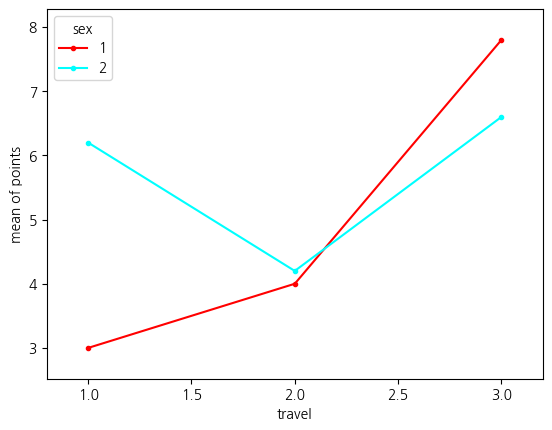

            count  mean       std
sex travel                       
1   1           5   3.0  1.000000
    2           5   4.0  1.000000
    3           5   7.8  0.836660
2   1           5   6.2  0.836660
    2           5   4.2  0.836660
    3           5   6.6  0.894427
                     sum_sq    df          F        PR(>F)
C(sex)             4.033333   1.0   4.938776  3.593950e-02
C(travel)         55.400000   2.0  33.918367  1.014700e-07
C(sex):C(travel)  25.266667   2.0  15.469388  4.830446e-05
Residual          19.600000  24.0        NaN           NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
{
  "question": "4-1",
  "method": "독립 집단 요인 모형의 Type II F 검정: sex 주효과",
  "H0": "sex 주효과가 없다",
  "H1": "sex 주효과가 있다",
  "statistic": 4.938775510204059,
  "p_value": 0.035939504821647664,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "독립 관측·정규 오차·등분산·식별 가능한 설계. 상호작용 유의 시 셀 평균과 조건부 효과를 우선 해석한다.",
  "conclusion": "귀무가설을 기각한다. poi

In [2]:
set_question('4-1')
travel=load('travel_example.csv');anova(travel,'points','sex','travel')
from statsmodels.graphics.factorplots import interaction_plot
interaction_plot(travel.travel,travel.sex,travel.points);plt.show()
print(travel.groupby(['sex','travel']).points.agg(['count','mean','std']))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_aov_model=anova(travel,'points','sex','travel')
report_anova(_aov_model,'points',['sex', 'travel'])